<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Hacker News API](https://github.com/Query-farm/vgi-hackernews)

Front-page rankings, stories, comment threads and user profiles from the public Hacker News API.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-hackernews/blob/main/notebooks/02_depth_changes_the_thread_you_count.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-hackernews/blob/main/notebooks/README.md)

## Depth changes the thread you count

Does a thread count mean direct replies or replies to replies? Read one historical root with a bounded depth, retain deleted and missing-body records, and compare parent/path identity before interpreting a count. The profile is a current public profile, not a reconstruction of the author at posting time.

### Change one bounded view

`MAX_DEPTH` accepts **1 or 2**. Increasing it asks the worker to traverse another level; it is not a filter on an unlimited download. Default responses are recorded from the official API; live mode is explicit and never falls back. Edit, then **Restart Kernel → Run All**.

In [1]:
MAX_DEPTH = 1  # Experiment: 2; bounded traversal
DATA_MODE = "replay"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.41":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.41"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, finish, prepare, prose, theme

check_runtime()
prepare("hackernews")

import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
from IPython.display import display  # noqa: E402

from hackernews_example import Source, selection  # noqa: E402

theme()

recording = Source(DATA_MODE, "thread")
session = connect(globals())
con = session.connection

### Connect the released worker

The public **v0.3.0** release runs in its own `uvx` environment. Shared setup isolates saved SQL credentials and keeps the parent connection on UTC. The Hacker News API requires no key.

`DATA_MODE="replay"` uses complete, hash-verified official responses through the worker's documented `HN_BASE_URL` setting. Its loopback server rejects unrecorded requests; it never forwards or falls back to the network. `"live"` explicitly reads the official public API. Capture and hydration are sequential operations, not an atomic snapshot. Content belongs to its authors; outputs below use identifiers and aggregates.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'hackernews' AS hn (
    TYPE vgi,
    LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-hackernews@v0.3.0 vgi-hackernews'
);

,Success


In [5]:
selection(MAX_DEPTH, "MAX_DEPTH", {1, 2})

### Keep the root, author profile and replies distinct

Item **8863** identifies the root independently of its display title. Its `kids` are direct child IDs; `descendants` is a separate provider count of live comments across the whole thread. Neither should be equated to every row a depth-limited walk returns. A lateral profile lookup follows the root's returned author rather than guessing a username.

In [6]:
%%sql
CREATE TABLE root_item AS SELECT * FROM hn.main.item(8863);
CREATE TABLE author_profile AS SELECT u.* FROM root_item r, LATERAL hn.main.user(r.author) u;
CREATE TABLE thread AS SELECT * FROM hn.main.comments(8863,max_depth:={{MAX_DEPTH}});
CREATE TABLE decoded AS SELECT *,hn.main.html_to_text(text) AS plain_text FROM thread;

,Count


In [7]:
%%sql root_context <<
SELECT r.id,r.author,r.created_at AS posted_at_utc,len(r.kids) AS direct_child_ids,
 r.descendants AS provider_live_descendants,u.created_at AS account_created_at_utc,
 u.username=r.author AS profile_identity_matches
FROM root_item r LEFT JOIN author_profile u ON r.author=u.username;

In [8]:
display(root_context)
assert len(root_context) == 1 and root_context.profile_identity_matches.all()
AS_OF = recording.as_of()
source_label = f"{DATA_MODE.title()} official Hacker News API · acquired {AS_OF[:19]} UTC\nRoot 8863; bounded traversal; content belongs to its authors"
r = root_context.iloc[0]
prose(
    f"The root lists **{int(r.direct_child_ids)} direct child IDs** and **{int(r.provider_live_descendants)} live descendants**. The returned profile matches its author. These are different grains and clocks: the profile is current at acquisition, while the root was posted in {r.posted_at_utc.year}."
)

,id,author,posted_at_utc,direct_child_ids,provider_live_descendants,account_created_at_utc,profile_identity_matches
0,8863,dhouston,2007-04-04 19:16:40+00:00,33,71,2007-03-29 17:31:02+00:00,True


The root lists **33 direct child IDs** and **71 live descendants**. The returned profile matches its author. These are different grains and clocks: the profile is current at acquisition, while the root was posted in 2007.

### Audit the rows before counting discussion

Keep all returned rows in the depth count. Separately report deleted/dead flags, absent bodies and absent authors. A missing body is not a zero-length message. The path carries sibling positions; its length should match depth, and a direct reply's parent should be the root.

In [9]:
%%sql depth_counts <<
SELECT depth,count(*) AS returned_rows,
 count(*) FILTER(WHERE deleted OR dead) AS deleted_or_dead,
 count(*) FILTER(WHERE text IS NULL) AS missing_body,
 count(*) FILTER(WHERE author IS NULL) AS missing_author,
 count(*) FILTER(WHERE plain_text IS NOT NULL) AS decoded_bodies
FROM decoded GROUP BY depth ORDER BY depth;

In [10]:
%%sql checks <<
SELECT count(*)=count(DISTINCT id) AS unique_items,
 bool_and(root_id=8863) AS correct_root,
 bool_and(depth BETWEEN 1 AND {{MAX_DEPTH}}) AS bounded_depth,
 bool_and(len(path)=depth) AS path_matches_depth,
 bool_and(depth<>1 OR parent=8863) AS direct_parent_matches,
 count(*) FILTER(WHERE text IS NULL)=count(*) FILTER(WHERE plain_text IS NULL) AS null_body_preserved,
 count(*) FILTER(WHERE depth=1) AS direct_reply_rows,
 (SELECT len(kids) FROM root_item) AS direct_child_ids
FROM decoded;

In [11]:
display(depth_counts)
display(checks)
assert checks.iloc[0, :6].all()
assert checks.direct_reply_rows.iloc[0] <= checks.direct_child_ids.iloc[0]
prose(
    f"At depth **{MAX_DEPTH}**, the worker returns **{int(depth_counts.returned_rows.sum())} rows**, of which **{int(depth_counts.missing_body.sum())} lack a body**. The returned direct replies cover **{int(checks.direct_reply_rows.iloc[0])} / {int(checks.direct_child_ids.iloc[0])}** root child IDs. Deleted, missing and deeper replies prevent treating every count as the same population."
)

,depth,returned_rows,deleted_or_dead,missing_body,missing_author,decoded_bodies
0,1,33,1,1,0,32


,unique_items,correct_root,bounded_depth,path_matches_depth,direct_parent_matches,null_body_preserved,direct_reply_rows,direct_child_ids
0,True,True,True,True,True,True,33,33


At depth **1**, the worker returns **33 rows**, of which **1 lack a body**. The returned direct replies cover **33 / 33** root child IDs. Deleted, missing and deeper replies prevent treating every count as the same population.

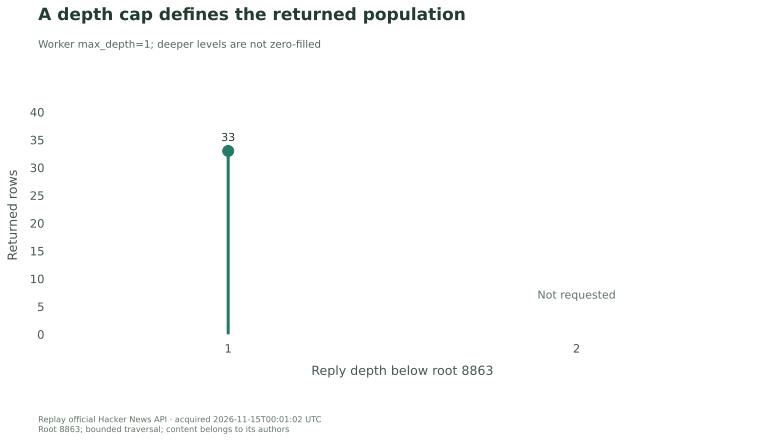

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.5))
ax.vlines(depth_counts.depth, 0, depth_counts.returned_rows, color="#257969", linewidth=3)
ax.scatter(depth_counts.depth, depth_counts.returned_rows, color="#257969", s=120, zorder=3)
for row in depth_counts.itertuples():
    ax.annotate(
        str(row.returned_rows),
        (row.depth, row.returned_rows),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
    )
if MAX_DEPTH == 1:
    ax.text(2, 0.15, "Not requested", transform=ax.get_xaxis_transform(), ha="center", color="#627468")
ax.set(
    xticks=[1, 2],
    xlabel="Reply depth below root 8863",
    ylabel="Returned rows",
    xlim=(0.5, 2.5),
    ylim=(0, depth_counts.returned_rows.max() * 1.3),
)
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
finish(
    fig,
    "A depth cap defines the returned population",
    f"Worker max_depth={MAX_DEPTH}; deeper levels are not zero-filled",
    source_label,
    name=f"thread-depth-{MAX_DEPTH}",
)

### Decode HTML without inventing missing content

The scalar `html_to_text` removes markup and decodes entities. Compare the lengths of the same non-null bodies before and after conversion. Length is a representation property, not quality or sentiment; no comment text needs to be reproduced to inspect it.

In [13]:
%%sql text_lengths <<
SELECT id,depth,length(text) AS html_characters,length(plain_text) AS plain_characters
FROM decoded WHERE text IS NOT NULL ORDER BY id;

In [14]:
display(text_lengths.head(8))
assert len(text_lengths) == int(depth_counts.decoded_bodies.sum())
assert text_lengths.plain_characters.ge(0).all()
changed = int((text_lengths.html_characters != text_lengths.plain_characters).sum())
prose(
    f"**{changed} of {len(text_lengths)} non-null bodies** change character count after decoding. All absent bodies remain SQL NULL; there is no zero-fill. Raw and plain counts describe the same selected comments."
)

,id,depth,html_characters,plain_characters
0,8865,1,31,31
1,8869,1,923,918
2,8870,1,11,11
3,8872,1,240,240
4,8873,1,230,229
5,8878,1,14,14
6,8881,1,279,279
7,8884,1,271,268


**18 of 32 non-null bodies** change character count after decoding. All absent bodies remain SQL NULL; there is no zero-fill. Raw and plain counts describe the same selected comments.

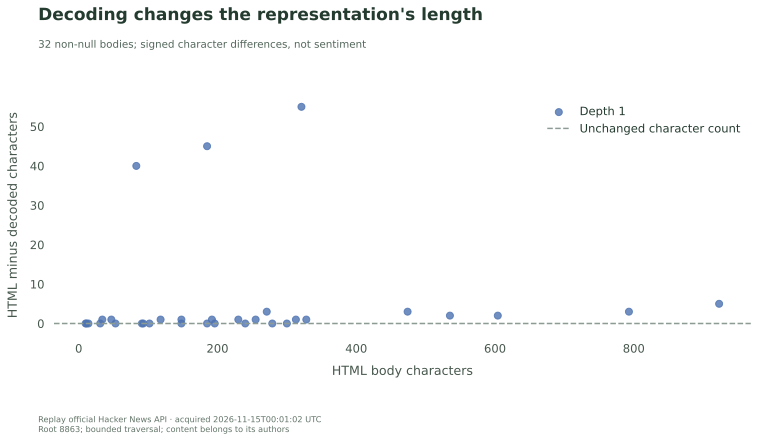

In [15]:
fig, ax = plt.subplots(figsize=(11, 6.5))
for depth, g in text_lengths.groupby("depth"):
    ax.scatter(
        g.html_characters, g.html_characters - g.plain_characters, s=50, alpha=0.8, label=f"Depth {depth}"
    )
ax.axhline(0, color="#8C9C94", linestyle="--", label="Unchanged character count")
ax.set(xlabel="HTML body characters", ylabel="HTML minus decoded characters")
ax.legend(loc="upper right")
finish(
    fig,
    "Decoding changes the representation's length",
    f"{len(text_lengths)} non-null bodies; signed character differences, not sentiment",
    source_label,
    name=f"thread-text-{MAX_DEPTH}",
)

### Experiment: include replies to replies

Change **MAX_DEPTH from 1 to 2**. The direct-reply records should remain identical in replay; only the second level joins them. Compare row counts, missing bodies and length pairs. This still does not read the whole thread or claim its total live-comment count. Live item edits can change values between acquisitions.

In [16]:
display(pd.DataFrame([recording.audit()]))

,mode,requests,distinct_paths,rejected,live_network_instrumented
0,replay,36,35,0,False


In [17]:
session.close()
recording.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-hackernews](https://github.com/Query-farm/vgi-hackernews)